In [43]:
from fastai.imports import *

In [44]:
df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
modes = df.mode().iloc[0]

In [45]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [47]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [48]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [49]:
def proc_data(df):
    df['Fare'] = df['Fare'].fillna(modes['Fare'])
    df['LogFare'] = np.log1p(df['Fare'])
    df['Embarked'] = pd.Categorical(df['Embarked'].fillna(modes['Embarked']))
    df['Sex'] = pd.Categorical(df['Sex'])

proc_data(df)
proc_data(test_df)

In [50]:
cats=["Sex","Embarked"]
conts = ["Age","SibSp","Parch","LogFare","Pclass"]
dep = 'Survived'

In [51]:
df.Sex.head()

0      male
1    female
2    female
3    female
4      male
Name: Sex, dtype: category
Categories (2, str): ['female', 'male']

In [52]:
df.Sex.cat.codes.head()

0    1
1    0
2    0
3    0
4    1
dtype: int8

We are going to do binanry split now for the processed data.

[Text(0.5, 1.0, 'Survival Count by Sex')]

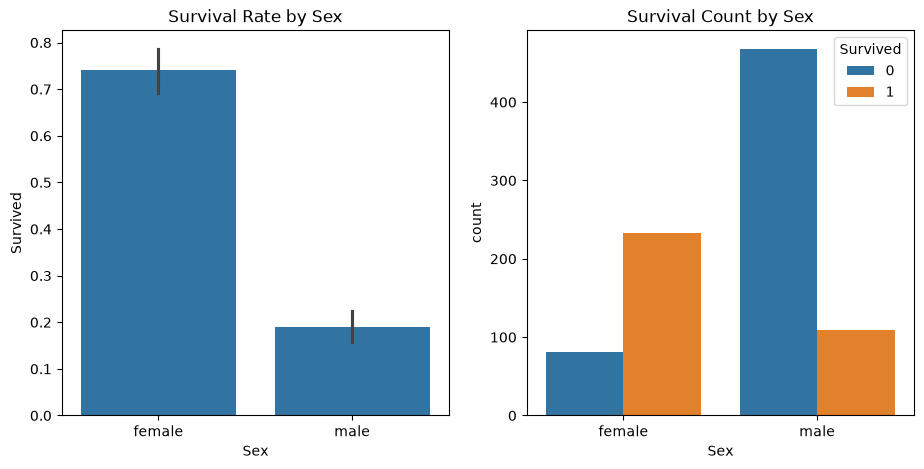

In [53]:
import seaborn as sns

figs, axes = plt.subplots(1, 2, figsize=(11, 5))
sns.barplot(data=df, y=dep, x ='Sex', ax=axes[0]).set(title='Survival Rate by Sex') 
sns.countplot(data=df, x='Sex', hue=dep, ax=axes[1]).set(title='Survival Count by Sex') 

Now gonnan convert categorical columns into integer codes

In [54]:
from sklearn.model_selection import train_test_split
random.seed(42)
trn_df, val_df = train_test_split(df, test_size=0.25)

In [55]:
trn_df[cats]= trn_df[cats].apply(lambda x: x.cat.codes)
val_df[cats]= val_df[cats].apply(lambda x: x.cat.codes)

In [56]:
def xs_y(df):
    xs = df[cats+conts].copy()
    return xs, df[dep] if dep in df else None

trn_xs, trn_y = xs_y(trn_df)
val_xs, val_y = xs_y(val_df)

In [57]:
preds = val_xs.Sex==0

In [58]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error(val_y, preds)

0.19730941704035873

In [59]:
preds = val_xs.LogFare>2.7
mean_absolute_error(val_y, preds)

0.38565022421524664

In [60]:
def _side_score(side, y):
    tot = side.sum()
    if tot<=1:
        return 0
    return y[side].std()*tot

In [61]:
def score(col,y,split):
    lhs = col <= split
    return (_side_score(lhs, y) +
            _side_score(~lhs, y)) / len(y)

In [62]:
nm="Age"
col = trn_xs[nm]
unq = np.unique(col)
unq.sort()

In [63]:
scores = np.array([
    score(col, trn_y, o)
    for o in unq if not np.isnan(o)
])
unq[scores.argmin()]

np.float64(6.0)

In [64]:
def min_col(df,nm):
    col, y = df[nm], df[dep]
    unq = col.dropna().unique()

    scores = np.array([
        score(col, y, o)
        for o in unq if not np.isnan(o)
    ])

    idx = scores.argmin()
    return unq[idx], scores[idx]

In [65]:
cols = cats+conts
{o: min_col(trn_df,o) for o in cols}

{'Sex': (np.int8(0), np.float64(0.41290328358819106)),
 'Embarked': (np.int8(0), np.float64(0.4832584523671172)),
 'Age': (np.float64(6.0), np.float64(0.48487136553168725)),
 'SibSp': (np.int64(4), np.float64(0.48348028030193974)),
 'Parch': (np.int64(0), np.float64(0.4838618511900296)),
 'LogFare': (np.float64(2.4437981558973862), np.float64(0.4629602549851667)),
 'Pclass': (np.int64(2), np.float64(0.4632484907273888))}

Creating decision tree

In [66]:
from sklearn.tree import DecisionTreeClassifier, export_graphviz

m = DecisionTreeClassifier(max_leaf_nodes=4).fit(trn_xs, trn_y)

Get:1 https://packages.microsoft.com/repos/microsoft-ubuntu-noble-prod noble InRelease [3600 B]
Get:2 http://archive.ubuntu.com/ubuntu noble InRelease [256 kB]       
Get:3 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]    
Get:4 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]      
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]      
Get:6 https://packages.microsoft.com/repos/microsoft-ubuntu-noble-prod noble/main amd64 Packages [743 kB]
Get:7 https://packages.microsoft.com/repos/microsoft-ubuntu-noble-prod noble/main all Packages [640 B]
Get:8 http://archive.ubuntu.com/ubuntu noble/main amd64 Packages [1808 kB]     
Get:9 http://archive.ubuntu.com/ubuntu noble/multiverse amd64 Packages [331 kB]
Get:10 http://archive.ubuntu.com/ubuntu noble/universe amd64 Packages [19.3 MB]
Get:11 http://archive.ubuntu.com/ubuntu noble/restricted amd64 Packages [117 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-updates/restricted am

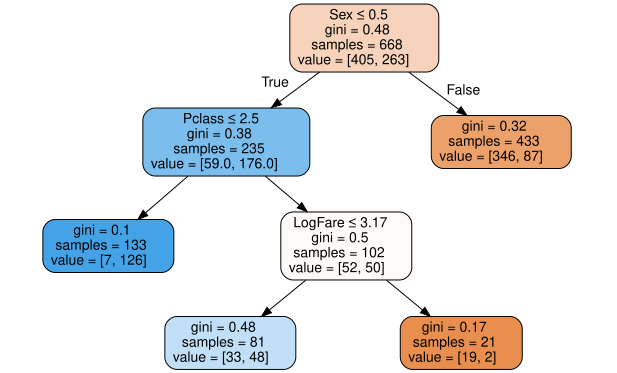

In [71]:
import re
import graphviz
import shutil

def draw_tree(t, df, size=10, ratio=0.6, precision=2, **kwargs):
    dot_data = export_graphviz(
        t,
        out_file=None,
        feature_names=df.columns,
        filled=True,
        rounded=True,
        special_characters=True,
        rotate=False,
        precision=precision,
        **kwargs
    )
    dot_data = re.sub(
        r'Tree \{',
        f'Tree {{ size={size}; ratio={ratio}',
        dot_data
    )
    return graphviz.Source(dot_data)

if shutil.which("dot") is None:
        if shutil.which("dot") is None:
            get_ipython().system(
                "sudo apt-get update && sudo apt-get install -y graphviz"
            )
draw_tree(m, trn_xs, size=10, ratio=0.6, precision=2)

In [72]:
def gini(cond):
    act = df.loc[cond,dep]
    return 1 - act.mean()**2 - (1-act).mean()**2

In [73]:
gini(df.Sex == 'female'), gini(df.Sex =='male')

(np.float64(0.3828350034484158), np.float64(0.3064437162277842))

In [74]:
mean_absolute_error(val_y, m.predict(val_xs))

0.18385650224215247

large decision tree

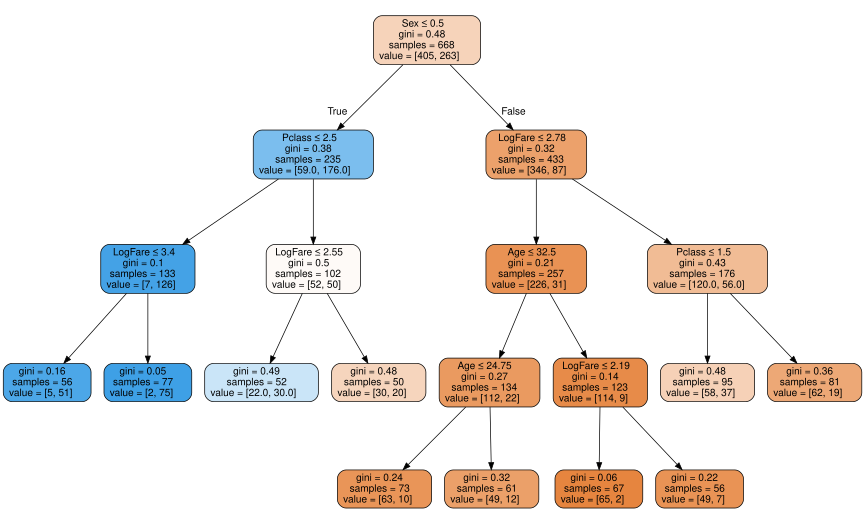

In [75]:
m=DecisionTreeClassifier(min_samples_leaf=50)
m.fit(trn_xs, trn_y)
draw_tree(m,trn_xs,size=12)

In [76]:
mean_absolute_error(val_y, m.predict(val_xs))

0.18834080717488788